<a href="https://colab.research.google.com/github/Umami-sketch/Tugas-Regresi-FSD/blob/main/B_Logistic_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Bagian B: Logistic Regression



## B1. Deskripsi Dataset
Dataset yang digunakan adalah **Rain in Australia** (`weatherAUS.csv`) yang bersumber dari platform Kaggle (Sumber: https://www.kaggle.com/datasets/jsphyg/weather-dataset-rattle-package). Dataset ini mencatat pengamatan cuaca harian dari berbagai stasiun meteorologi di Australia selama sekitar 10 tahun.
* **Jumlah Data & Fitur**: Berisi 145.460 baris dan 23 kolom pengamatan cuaca numerik serta kategorikal.
* **Variabel Target**: `RainTomorrow`, yaitu variabel kategorikal biner yang memprediksi apakah esok hari akan turun hujan atau tidak (`Yes` atau `No`).
* **Fitur Utama**: Suhu (`MinTemp`, `MaxTemp`), curah hujan (`Rainfall`), penguapan (`Evaporation`), durasi sinar matahari (`Sunshine`), kecepatan angin (`WindGustSpeed`), kelembapan (`Humidity9am`, `Humidity3pm`), tekanan atmosfer (`Pressure9am`, `Pressure3pm`), serta tutupan awan (`Cloud9am`, `Cloud3pm`).

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Memuat data dari URL

url_b = "https://raw.githubusercontent.com/Umami-sketch/Tugas-Regresi-FSD/refs/heads/main/data/weatherAUS.csv"
df_b = pd.read_csv(url_b)

print(df_b.shape)
df_b.head()

(145460, 23)


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


## B2. Eksplorasi dan Visualisasi Data
Pada tahap ini dilakukan pengecekan distribusi kelas target, persebaran nilai fitur numerik terhadap kelas target, dan hubungan korelasi antarfitur.

/tmp/ipykernel_5096/3798476956.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_b, x='RainTomorrow', palette='Set2', ax=axes[0])
/tmp/ipykernel_5096/3798476956.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_b, x='RainTomorrow', y='Humidity3pm', palette='Set2', ax=axes[1])


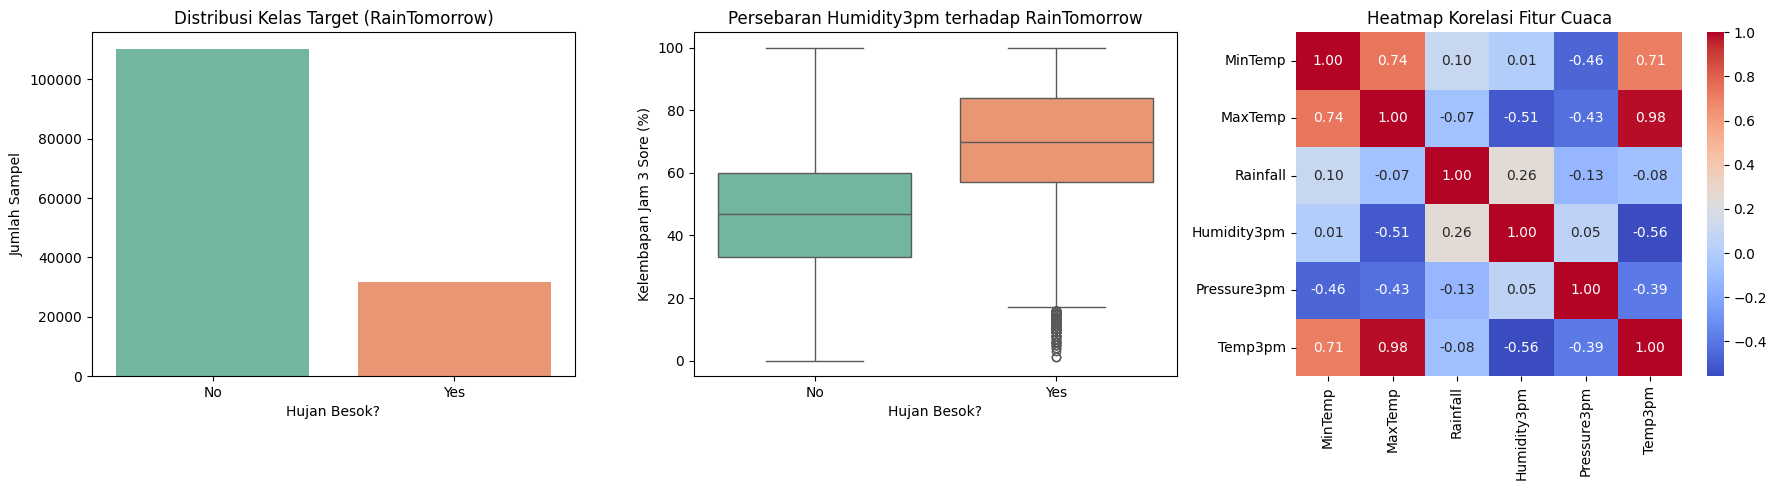

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Bar Chart Distribusi Kelas Target
sns.countplot(data=df_b, x='RainTomorrow', palette='Set2', ax=axes[0])
axes[0].set_title('Distribusi Kelas Target (RainTomorrow)')
axes[0].set_xlabel('Hujan Besok?')
axes[0].set_ylabel('Jumlah Sampel')

# 2. Box Plot Kelembapan Jam 3 Sore (Humidity3pm) per Kelas
sns.boxplot(data=df_b, x='RainTomorrow', y='Humidity3pm', palette='Set2', ax=axes[1])
axes[1].set_title('Persebaran Humidity3pm terhadap RainTomorrow')
axes[1].set_xlabel('Hujan Besok?')
axes[1].set_ylabel('Kelembapan Jam 3 Sore (%)')

# 3. Heatmap Korelasi Fitur Cuaca Utama
selected_corr_cols = ['MinTemp', 'MaxTemp', 'Rainfall', 'Humidity3pm', 'Pressure3pm', 'Temp3pm']
sns.heatmap(df_b[selected_corr_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f", ax=axes[2])
axes[2].set_title('Heatmap Korelasi Fitur Cuaca')

plt.tight_layout()
plt.show()

**Temuan Visualisasi (B2)**:
1. **Ketidakseimbangan Kelas**: Sekitar 78% data menunjukkan label `No` dan hanya 22% berlabel `Yes`. Kondisi *imbalanced class* ini perlu ditangani agar model tidak bias menebak `No` terus-menerus.
2. **Karakteristik Kelembapan Sore**: Boxplot menunjukkan bahwa hari yang esoknya hujan (`Yes`) memiliki median kelembapan sore hari (`Humidity3pm`) yang jauh lebih tinggi (~75%) dibandingkan hari yang esoknya tidak hujan (~50%).
3. **Korelasi Antarfitur**: Fitur suhu (`MinTemp`, `MaxTemp`, `Temp3pm`) memiliki multikolinearitas yang sangat kuat satu sama lain, sehingga nanti hanya fitur yang paling berpengaruh yang akan dipilih.

## B3. Preprocessing
Tahapan pembersihan data meliputi pembuangan baris target kosong, penghapusan kolom non-meteorologis, penanganan missing values, encoding data, serta mitigasi imbalanced class.

In [ ]:
# 1. Hapus baris yang label targetnya kosong
df_clean = df_b.dropna(subset=['RainTomorrow']).copy()

# 2. Buang kolom Date dan Location agar model fokus pada variabel meteorologi
df_clean = df_clean.drop(columns=['Date', 'Location'])

# 3. Pisahkan kolom numerik dan kategorikal
num_cols = df_clean.select_dtypes(include=[np.number]).columns
cat_cols = df_clean.select_dtypes(include=['object']).columns.drop('RainTomorrow')

# Imputasi: median untuk numerik, modus untuk kategorikal
for col in num_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

for col in cat_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

# 4. Encoding Target Biner (No = 0, Yes = 1)
df_clean['RainTomorrow'] = df_clean['RainTomorrow'].map({'No': 0, 'Yes': 1})

# 5. One-Hot Encoding untuk fitur kategorikal lainnya
df_clean = pd.get_dummies(df_clean, columns=cat_cols, drop_first=True)

print("Dimensi data bersih:", df_clean.shape)
print("\nDistribusi Target:")
print(df_clean['RainTomorrow'].value_counts(normalize=True) * 100)

Dimensi data bersih: (142193, 63)

Distribusi Target:
RainTomorrow
0    77.581878
1    22.418122
Name: proportion, dtype: float64


**Alasan Keputusan Preprocessing (B3)**:
* Baris dengan target `NaN` dihapus karena model klasifikasi terawasi membutuhkan label supervisi yang pasti.
* Imputasi nilai hilang menggunakan **median** untuk fitur numerik dipilih agar tidak terdistorsi oleh data ekstrem (*outlier*), sementara fitur kategorikal menggunakan nilai **modus**.
* Fitur teks dikonversi dengan **One-Hot Encoding** agar dapat diolah secara matematis oleh algoritma regresi.
* Penanganan ketimpangan kelas target dilakukan menggunakan parameter `stratify` saat pembagian data serta `class_weight='balanced'` pada model.

## B4. Pemilihan Fitur (Feature Selection)
Pemilihan fitur dilakukan secara objektif menggunakan metode statistik `SelectKBest` dengan uji ANOVA F-value (`f_classif`) untuk memilih 8 fitur yang memiliki hubungan paling kuat terhadap kejadian hujan besok.

In [ ]:
from sklearn.feature_selection import SelectKBest, f_classif

X = df_clean.drop(columns=['RainTomorrow'])
y = df_clean['RainTomorrow']

# Memilih 8 fitur terbaik
selector = SelectKBest(score_func=f_classif, k=8)
selector.fit(X, y)
selected_features = X.columns[selector.get_support()]

print("Fitur yang dipertahankan:")
for col in selected_features:
    print(f"- {col}")

Fitur yang dipertahankan:
- Rainfall
- Sunshine
- Humidity9am
- Humidity3pm
- Pressure9am
- Cloud9am
- Cloud3pm
- RainToday_Yes


**Alasan Pemilihan Fitur (B4)**:
* Fitur seperti `Humidity3pm`, `Sunshine`, `Cloud3pm`, dan `RainToday_Yes` memiliki nilai statistik F tertinggi, menandakan kontribusi pembeda yang paling signifikan terhadap target.
* Fitur-fitur lain yang memiliki korelasi lemah atau berlebihan (redundansi suhu) disingkirkan untuk mempercepat komputasi dan meminimalkan multikolinearitas.

## B5. Pembagian Data (Train-Test Split)
Data dibagi menjadi 80% data latih dan 20% data uji. Penggunaan parameter `stratify=y` memastikan bahwa proporsi kelas hujan tetap konsisten pada kedua subset. Seluruh fitur kemudian distandardisasi menggunakan `StandardScaler`.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_selected = X[selected_features]

# Split 80:20 secara terstratifikasi
X_train, X_test, y_train, y_test = train_test_split(
    X_selected, y, test_size=0.20, random_state=42, stratify=y
)

# Standardisasi fitur numerik
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Dimensi X_train: {X_train_scaled.shape}")
print(f"Dimensi X_test : {X_test_scaled.shape}")

Dimensi X_train: (113754, 8)
Dimensi X_test : (28439, 8)


## B6. Pemodelan (Logistic Regression)
Model `LogisticRegression` dilatih menggunakan opsi `class_weight='balanced'` untuk memberikan penalti yang proporsional pada kelas minoritas (kejadian hujan).

In [ ]:
from sklearn.linear_model import LogisticRegression

# Inisialisasi dan pelatihan model
model_b = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
model_b.fit(X_train_scaled, y_train)

# Tabel koefisien log-odds dan odds ratio
coef_df = pd.DataFrame({
    'Fitur': selected_features,
    'Koefisien (Log-Odds)': model_b.coef_[0],
    'Odds Ratio': np.exp(model_b.coef_[0])
}).sort_values(by='Koefisien (Log-Odds)', ascending=False)

print(f"Intercept: {model_b.intercept_[0]:.4f}\n")
coef_df

Intercept: -0.5094



,Fitur,Koefisien (Log-Odds),Odds Ratio
3,Humidity3pm,0.948390,2.581550
6,Cloud3pm,0.302997,1.353910
7,RainToday_Yes,0.185856,1.204249
0,Rainfall,0.121006,1.128631
5,Cloud9am,0.010794,1.010852
2,Humidity9am,-0.005382,0.994633
1,Sunshine,-0.333632,0.716317
4,Pressure9am,-0.580144,0.559818


**Interpretasi Koefisien (B6)**:
* **Koefisien Positif**: Fitur seperti `Humidity3pm` memiliki nilai koefisien positif paling tinggi. Artinya, setiap kenaikan kelembapan sore hari akan meningkatkan log-odds terjadinya hujan esok hari secara drastis (Odds Ratio > 1).
* **Koefisien Negatif**: Fitur seperti `Sunshine` dan `Pressure3pm` bertanda negatif, yang berarti semakin banyak sinar matahari atau semakin tinggi tekanan udara sore hari, peluang terjadinya hujan besok akan menurun (Odds Ratio < 1).

## B7. Evaluasi Model
Evaluasi dilakukan dengan menghitung metrik Accuracy, Precision, Recall, dan F1-Score, serta menampilkan visualisasi Confusion Matrix dan kurva ROC beserta nilai AUC.

Accuracy : 0.7703
Precision: 0.4919
Recall   : 0.7517
F1-Score : 0.5947
ROC-AUC  : 0.8442


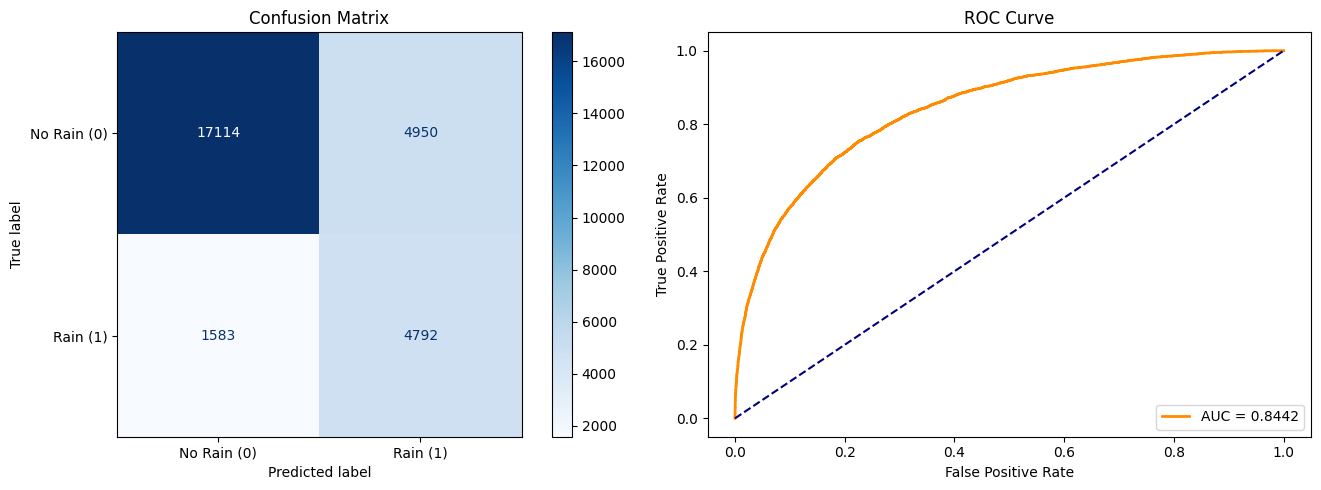

In [ ]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    ConfusionMatrixDisplay, roc_curve, roc_auc_score
)

# Prediksi label dan probabilitas
y_pred = model_b.predict(X_test_scaled)
y_pred_proba = model_b.predict_proba(X_test_scaled)[:, 1]

# Perhitungan metrik
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score : {f1_score(y_test, y_pred):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, y_pred_proba):.4f}")

# Visualisasi Confusion Matrix & ROC Curve
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Plot Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=['No Rain (0)', 'Rain (1)'],
    cmap='Blues', ax=ax[0]
)
ax[0].set_title("Confusion Matrix")

# Plot ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
ax[1].plot(fpr, tpr, color='darkorange', lw=2, label=f"AUC = {roc_auc_score(y_test, y_pred_proba):.4f}")
ax[1].plot([0, 1], [0, 1], color='navy', linestyle='--')
ax[1].set_xlabel("False Positive Rate")
ax[1].set_ylabel("True Positive Rate")
ax[1].set_title("ROC Curve")
ax[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

## B8. Analisis Performa dan Keterbatasan

* **Metrik Paling Relevan**: Nilai Recall (0.7517) dan ROC-AUC (0.8442) adalah indikator utama performa model. Untuk mitigasi cuaca, mendeteksi sebanyak mungkin hari yang berpotensi hujan (memaksimalkan True Positive) jauh lebih penting daripada sekadar akurasi, agar sistem peringatan dini tidak melewatkan cuaca buruk.

* **Analisis Kesalahan (Confusion Matrix)**: Dari total 28.439 data uji, model berhasil mendeteksi 4.792 hari hujan dengan benar (True Positive), tetapi menghasilkan 4.950 prediksi False Positive (memprediksi hujan padahal kenyataannya cerah). Tingginya angka ini wajar karena kita menggunakan penyeimbang bobot (class_weight='balanced'), sehingga model sengaja dibuat lebih waspada menebak potensi hujan.

* **Keterbatasan Model**: Nilai Precision berada di angka 0.4919 karena batas keputusan regresi logistik bersifat linier. Kondisi atmosfer riil memiliki dinamika non-linear yang kompleks (misalnya kombinasi ekstrem antara kelembapan sore dan tekanan udara pagi), sehingga model linear ini memiliki batas kemampuan dalam memisahkan hari cerah dan hari hujan secara sempurna.   

   